# XGBoost dự đoán khách hàng giá trị cao và so sánh với GMM của Thuận


## Import thư viện và đọc dữ liệu

In [2]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 8.4 MB/s eta 0:00:06
   ---- ----------------------------------- 5.0/48.9 MB 14.3 MB/s eta 0:00:04
   ------- -------------------------------- 8.7/48.9 MB 15.8 MB/s eta 0:00:03
   ---------- ----------------------------- 12.6/48.9 MB 16.8 MB/s eta 0:00:03
   ------------- -------------------------- 16.8/48.9 MB 17.0 MB/s eta 0:00:02
   ---------------- ----------------------- 20.7/48.9 MB 17.4 MB/s eta 0:00:02
   -------------------- ------------------- 25.2/48.9 MB 18.3 MB/s eta 0:00:02
   ------------------------ --------------- 29.6/48.9 MB 18.6 MB/s eta 0:00:02
   --------------------------- ------------ 34.1/48.9 MB 19.0 MB/s eta 0:00:01
   ------------------------------- -------- 39.1/48.9 MB 19.4 MB/s eta 0:00:01
   ---------------------------------- ----- 42.7/48.9 MB 19.1 MB/s eta 0:00:01
   ---------------------------------------  48.0/48.9 MB 19.6 MB/


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys, hashlib, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.inspection import permutation_importance
import sklearn
print("xgboost:", xgboost.__version__, "| scikit-learn:", sklearn.__version__)

xgboost: 3.4.1 | scikit-learn: 1.9.1


In [4]:
# Tự tìm thư mục project; thư mục notebook lấy theo vị trí hiện tại để không phụ thuộc tên thư mục
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(f for f in [current_dir, *current_dir.parents]
                    if (f / "data" / "raw" / "Online Retail.xlsx").exists())
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "Online Retail.xlsx"
NB_DIR = current_dir
FIG_DIR = NB_DIR / "figure"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing import SPECIAL_CODES, OUTLIER_COLS, OUTLIER_K, RAW_SHA256

sha = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
print("SHA-256 khớp với raw của dự án:", sha == RAW_SHA256)
assert sha == RAW_SHA256

df_raw = pd.read_excel(RAW_PATH, sheet_name="Online Retail")
print("Kích thước dữ liệu:", df_raw.shape)

SHA-256 khớp với raw của dự án: True
Kích thước dữ liệu: (541909, 8)


## Cấu hình thí nghiệm

In [5]:
RANDOM_STATE = 42
WINDOW_START = pd.Timestamp("2010-12-01")
CUTOFF = pd.Timestamp("2011-09-01")
END_DATE = pd.Timestamp("2011-12-10")
TOP_Q = 0.80
TEST_SIZE = 0.20

FEATURES = ["Recency", "Frequency", "Monetary", "n_stock_codes", "total_quantity", "active_days",
            "observed_span_days", "observed_tenure_days", "avg_purchase_gap_days",
            "avg_order_value", "avg_quantity_per_order"]
RFM = ["Recency", "Frequency", "Monetary"]

results = {}
print("Mốc cắt:", CUTOFF.date(), "| top", round((1 - TOP_Q) * 100), "% | seed", RANDOM_STATE)

Mốc cắt: 2011-09-01 | top 20 % | seed 42


## Cohort 4.327 khách

In [6]:
FEATURE_CSV = (PROJECT_ROOT / "notebooks" / "02_baseline_kmeans" / "12-11-2026-hieu-kmeans"
               / "data" / "customer_features.csv")
ref_feat = pd.read_csv(FEATURE_CSV)
assert ref_feat["CustomerID"].is_unique
cohort_ids = set(ref_feat["CustomerID"])
results["n_cohort"] = len(cohort_ids)
print("Số khách trong cohort:", len(cohort_ids))

Số khách trong cohort: 4327


## Làm sạch dòng mua và dòng hủy

Giữ nguyên quy trình của notebook Random Forest: dòng mua theo quy tắc legacy `clean_data`; dòng hủy lọc
bằng cùng mã dịch vụ và cùng ngưỡng ngoại lai (dùng |Quantity|).

In [7]:
def normalise(raw):
    df = raw.rename(columns={"InvoiceNo": "Invoice", "UnitPrice": "Price", "CustomerID": "Customer ID"}).copy()
    df["Description"] = df["Description"].fillna("Unknown Product").astype(str).str.strip().str.upper()
    for col in ["Invoice", "StockCode"]:
        df[col] = df[col].astype(str).str.strip().str.upper()
    df["Country"] = df["Country"].astype(str).str.strip().replace({"EIRE": "Ireland"})
    return df.drop_duplicates()

base = normalise(df_raw)
is_cancel = base["Invoice"].str.startswith("C")
not_special = ~base["StockCode"].isin(SPECIAL_CODES)

buy_pre = base[~is_cancel & (base["Quantity"] > 0) & (base["Price"] > 0) & not_special].copy()

bounds = {}
for col in OUTLIER_COLS:
    x = np.log1p(buy_pre[col])
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    bounds[col] = (q1 - OUTLIER_K * iqr, q3 + OUTLIER_K * iqr)

def within_bounds(df, quantity):
    ok = pd.Series(True, index=df.index)
    for col, series in [("Quantity", quantity), ("Price", df["Price"])]:
        x = np.log1p(series)
        lo, hi = bounds[col]
        ok &= (x >= lo) & (x <= hi)
    return ok

buy_all = buy_pre[within_bounds(buy_pre, buy_pre["Quantity"])].copy()
ret_pre = base[is_cancel & base["Customer ID"].notna() & (base["Price"] > 0) & not_special].copy()
assert (ret_pre["Quantity"] < 0).all()
ret_all = ret_pre[within_bounds(ret_pre, -ret_pre["Quantity"])].copy()

def to_cohort(df):
    df = df[df["Customer ID"].notna()].copy()
    df["CustomerID"] = df["Customer ID"].astype(int)
    df["Value"] = df["Quantity"] * df["Price"]
    return df[df["CustomerID"].isin(cohort_ids)]

buy_c, ret_c = to_cohort(buy_all), to_cohort(ret_all)
assert set(buy_c["CustomerID"]) == cohort_ids, "Cohort tái dựng không trùng 4.327 khách gốc"
print("Dòng mua của cohort:", len(buy_c), "| dòng hủy của cohort:", len(ret_c))

Dòng mua của cohort: 390987 | dòng hủy của cohort: 8376


## Hàm tạo feature và kiểm tra tái dựng

In [8]:
def build_features(buy, ret, ref_date, net_returns):
    # Một dòng/khách; CustomerID chỉ là chỉ mục, không phải feature
    b = buy.copy()
    b["PurchaseDay"] = b["InvoiceDate"].dt.normalize()
    f = b.groupby("CustomerID").agg(
        LastPurchase=("InvoiceDate", "max"), FirstPurchase=("InvoiceDate", "min"),
        Frequency=("Invoice", "nunique"), Monetary=("Value", "sum"),
        n_stock_codes=("StockCode", "nunique"), total_quantity=("Quantity", "sum"),
        active_days=("PurchaseDay", "nunique"))
    f["Recency"] = (ref_date - f["LastPurchase"].dt.normalize()).dt.days
    f["observed_span_days"] = (f["LastPurchase"] - f["FirstPurchase"]).dt.total_seconds() / 86400
    f["observed_tenure_days"] = (ref_date - f["FirstPurchase"]).dt.total_seconds() / 86400
    orders = (b.groupby(["CustomerID", "Invoice"], as_index=False)["InvoiceDate"].min()
                .sort_values(["CustomerID", "InvoiceDate", "Invoice"]))
    orders["gap"] = orders.groupby("CustomerID")["InvoiceDate"].diff().dt.total_seconds() / 86400
    f["avg_purchase_gap_days"] = orders.groupby("CustomerID")["gap"].mean()
    if net_returns:   # đối trừ hủy trong cùng cửa sổ; Value của dòng hủy là số âm
        f["Monetary"] = f["Monetary"] + ret.groupby("CustomerID")["Value"].sum().reindex(f.index).fillna(0.0)
    f["avg_order_value"] = f["Monetary"] / f["Frequency"]
    f["avg_quantity_per_order"] = f["total_quantity"] / f["Frequency"]
    return f[FEATURES]

rebuilt = build_features(buy_c, ret_c, END_DATE, net_returns=False)
reference = ref_feat.set_index("CustomerID")[FEATURES]
match = {c: bool(np.allclose(rebuilt.loc[reference.index, c], reference[c], rtol=1e-9, atol=1e-6, equal_nan=True))
         for c in FEATURES}
print("Số cột feature khớp bộ feature gốc:", sum(match.values()), "/", len(FEATURES))
assert all(match.values())

Số cột feature khớp bộ feature gốc: 11 / 11


Cohort tái dựng đúng 4.327 khách và cả 11 feature khớp bộ feature gốc, nên các hàm làm sạch và `build_features` giống hệt notebook Random Forest.

## Chia giai đoạn, tạo feature và nhãn

In [9]:
buy_feat = buy_c[(buy_c["InvoiceDate"] >= WINDOW_START) & (buy_c["InvoiceDate"] < CUTOFF)]
ret_feat = ret_c[(ret_c["InvoiceDate"] >= WINDOW_START) & (ret_c["InvoiceDate"] < CUTOFF)]
buy_lab = buy_c[buy_c["InvoiceDate"] >= CUTOFF]
ret_lab = ret_c[ret_c["InvoiceDate"] >= CUTOFF]

# Chống rò rỉ: feature hoàn toàn trước mốc, nhãn hoàn toàn từ mốc
assert buy_feat["InvoiceDate"].max() < CUTOFF <= buy_lab["InvoiceDate"].min()
assert ret_feat["InvoiceDate"].max() < CUTOFF <= ret_lab["InvoiceDate"].min()

X_all = build_features(buy_feat, ret_feat, CUTOFF, net_returns=True)
assert "CustomerID" not in X_all.columns and X_all.index.name == "CustomerID"
assert list(X_all.columns) == FEATURES and X_all.index.is_unique

def net_value(buy, ret, ids):
    s = buy.groupby("CustomerID")["Value"].sum().add(ret.groupby("CustomerID")["Value"].sum(), fill_value=0.0)
    return s.reindex(ids).fillna(0.0)

net_label = net_value(buy_lab, ret_lab, X_all.index)
y_tmp = ((net_label >= net_label.quantile(TOP_Q)) & (net_label > 0)).astype(int)   # chỉ để stratify
idx_train, idx_test = train_test_split(X_all.index, test_size=TEST_SIZE, stratify=y_tmp, random_state=RANDOM_STATE)
thr_gbp = net_label.loc[idx_train].quantile(TOP_Q)                                  # ngưỡng chỉ từ train
y = ((net_label >= thr_gbp) & (net_label > 0)).astype(int)
X_train, X_test = X_all.loc[idx_train], X_all.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# Đối chiếu với kết quả Random Forest đã commit (cùng khách, cùng nhãn, cùng tập test)
expected = {"n_features": 3306, "n_train": 2644, "n_test": 662, "thr": 922, "pos_train": 529, "pos_test": 133}
got = {"n_features": len(X_all), "n_train": len(X_train), "n_test": len(X_test), "thr": round(thr_gbp),
       "pos_train": int(y_train.sum()), "pos_test": int(y_test.sum())}
print("Kết quả tái dựng:", got)
assert got == expected, "Protocol không trùng với notebook Random Forest"

results["protocol"] = got
results["split"] = {"rate_train": float(y_train.mean()), "rate_test": float(y_test.mean()),
                    "n_nan_gap": int(X_all["avg_purchase_gap_days"].isna().sum())}

Kết quả tái dựng: {'n_features': 3306, 'n_train': 2644, 'n_test': 662, 'thr': 922, 'pos_train': 529, 'pos_test': 133}


Protocol tái lập đúng notebook Random Forest: 3.306 khách có feature, train 2.644 (529 nhãn 1, 20,0%), test 662 (133 nhãn 1, 20,1%), ngưỡng 922 GBP. Nhờ vậy mọi mô hình bên dưới được chấm trên cùng 662 khách test. Chỉ `avg_purchase_gap_days` thiếu giá trị (1.375 khách), được giữ NaN cho XGBoost.

## Hàm đánh giá và baseline

In [10]:
def precision_at_k(y_true, score, frac=0.10):
    y_true, score = np.asarray(y_true), np.asarray(score)
    k = max(1, int(round(frac * len(y_true))))
    return y_true[np.argsort(-score, kind="stable")[:k]].mean()

def recall_at_frac(y_true, score, frac=0.20):
    y_true, score = np.asarray(y_true), np.asarray(score)
    k = max(1, int(round(frac * len(y_true))))
    return y_true[np.argsort(-score, kind="stable")[:k]].sum() / y_true.sum()

def rank_metrics(y_true, score):
    p10 = precision_at_k(y_true, score)
    return {"PR-AUC": float(average_precision_score(y_true, score)), "ROC-AUC": float(roc_auc_score(y_true, score)),
            "Precision@10%": float(p10), "Lift@10%": float(p10 / np.mean(y_true)),
            "Recall@20%": float(recall_at_frac(y_true, score))}

def class_metrics(y_true, pred):
    return {"Precision": float(precision_score(y_true, pred, zero_division=0)),
            "Recall": float(recall_score(y_true, pred)), "F1": float(f1_score(y_true, pred))}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def oof_threshold(model, X, y):
    # Ngưỡng cho F1 lớn nhất trên xác suất out-of-fold của train; test không tham gia
    oof = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y, oof)
    f1c = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1c)]), float(f1c.max())

score_base = X_test["Monetary"].to_numpy()
thr_base = X_train["Monetary"].quantile(TOP_Q)
pred_base = (X_test["Monetary"] >= thr_base).astype(int)
print("Baseline: Monetary quá khứ", {k: round(v, 3) for k, v in rank_metrics(y_test, score_base).items()})

Baseline: Monetary quá khứ {'PR-AUC': 0.678, 'ROC-AUC': 0.842, 'Precision@10%': 0.788, 'Lift@10%': 3.922, 'Recall@20%': 0.602}


## Random Forest tham chiếu (tham số đã chọn ở notebook trước)

In [11]:
rf_ref = RandomForestClassifier(n_estimators=500, min_samples_leaf=10, max_features="sqrt",
                                class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)
rf_ref.fit(X_train, y_train)
p_rf = rf_ref.predict_proba(X_test)[:, 1]
pr_rf = average_precision_score(y_test, p_rf)
print(f"PR-AUC test của Random Forest chạy lại: {pr_rf:.4f} (notebook Random Forest đã commit: 0,6718)")
assert abs(pr_rf - 0.6718) < 0.002, "Không tái lập được kết quả Random Forest"

PR-AUC test của Random Forest chạy lại: 0.6718 (notebook Random Forest đã commit: 0,6718)


## XGBoost: tinh chỉnh siêu tham số (11 feature)

In [12]:
spw = float((y_train == 0).sum() / (y_train == 1).sum())   # cân bằng lớp, tính chỉ từ train
xgb_base = XGBClassifier(subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, scale_pos_weight=spw,
                         tree_method="hist", eval_metric="aucpr", random_state=RANDOM_STATE, n_jobs=2)
param_grid_xgb = {"max_depth": [2, 3, 4], "learning_rate": [0.03, 0.1],
                  "n_estimators": [200, 400], "min_child_weight": [1, 5]}

def tune(X, yv):
    gs = GridSearchCV(xgb_base, param_grid_xgb, scoring="average_precision", cv=cv, refit=True, n_jobs=1)
    return gs.fit(X, yv)   # NaN ở avg_purchase_gap_days được XGBoost xử lý trực tiếp

gs_xgb = tune(X_train, y_train)
cv_xgb = (pd.DataFrame(gs_xgb.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
          .sort_values("rank_test_score").reset_index(drop=True))
results["xgb11"] = {"best_params": gs_xgb.best_params_, "best_cv_pr_auc": float(gs_xgb.best_score_), "scale_pos_weight": spw}
print(f"scale_pos_weight = {spw:.3f}")
print("Tham số tốt nhất:", gs_xgb.best_params_)
print(f"PR-AUC trung bình 5-fold: {gs_xgb.best_score_:.3f}")
cv_xgb.head(8).round(4)

scale_pos_weight = 3.998
Tham số tốt nhất: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 200}
PR-AUC trung bình 5-fold: 0.691


,params,mean_test_score,std_test_score,rank_test_score
0,"{'learning_rate': 0.03, 'max_depth': 2, 'min_c...",0.6909,0.0320,1
1,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",0.6889,0.0284,2
2,"{'learning_rate': 0.03, 'max_depth': 2, 'min_c...",0.6877,0.0286,3
3,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",0.6872,0.0298,4
4,"{'learning_rate': 0.03, 'max_depth': 2, 'min_c...",0.6870,0.0314,5
5,"{'learning_rate': 0.03, 'max_depth': 2, 'min_c...",0.6855,0.0289,6
6,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c...",0.6828,0.0297,7
7,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",0.6825,0.0265,8


Cấu hình tốt nhất: `learning_rate=0,03`, `max_depth=2`, `min_child_weight=1`, `n_estimators=200`, PR-AUC 5-fold 0,687 (Random Forest: 0,689). Cả bốn tham số đều rơi vào giá trị nhỏ nhất của lưới, tức mô hình đơn giản nhất thắng, và độ lệch chuẩn giữa các fold khoảng 0,03 nên các cấu hình đầu bảng gần như không phân biệt được. Điều này cho thấy tín hiệu dự đoán khá đơn giản. Bản chỉ RFM chọn cùng tham số, PR-AUC 5-fold 0,680.

## XGBoost chỉ dùng RFM (so sánh công bằng với GMM)

In [13]:
gs_xgb_rfm = tune(X_train[RFM], y_train)
results["xgb_rfm"] = {"best_params": gs_xgb_rfm.best_params_, "best_cv_pr_auc": float(gs_xgb_rfm.best_score_)}
print("Tham số tốt nhất:", gs_xgb_rfm.best_params_)
print(f"PR-AUC trung bình 5-fold: {gs_xgb_rfm.best_score_:.3f} (11 feature: {gs_xgb.best_score_:.3f})")

Tham số tốt nhất: {'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 200}
PR-AUC trung bình 5-fold: 0.680 (11 feature: 0.691)


## GMM của Thuận fit trên giai đoạn trước mốc

Dùng đúng quy trình của Thuận: RFM gộp (Recency, Frequency, Monetary chưa đối trừ hủy), `StandardScaler`,
quét k = 2..10 và 4 loại hiệp phương sai, chọn mô hình có BIC thấp nhất trong số mô hình hội tụ và mỗi cụm
chiếm ít nhất 1% số khách. Cấu hình A dùng RFM thô, cấu hình B thêm `log1p`. Chỉ fit trên tập train, không
dùng nhãn khi tạo cụm. Nhãn chỉ dùng để tính tỷ lệ nhãn 1 của từng cụm trên train; điểm của mỗi khách là
tổng xác suất thuộc cụm nhân với tỷ lệ đó.

In [14]:
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_FRAC = 0.01

rfm_gross = build_features(buy_feat, ret_feat, CUTOFF, net_returns=False)[RFM].astype(float)
assert (rfm_gross > 0).all().all()
R_train, R_test = rfm_gross.loc[idx_train], rfm_gross.loc[idx_test]

def gmm_fit(Xs, k, cov):
    return GaussianMixture(n_components=k, covariance_type=cov, n_init=10, max_iter=300, tol=1e-3,
                           reg_covar=1e-6, init_params="kmeans", random_state=RANDOM_STATE).fit(Xs)

def gmm_select(Xs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = gmm_fit(Xs, k, cov)
            sizes = np.bincount(gm.predict(Xs), minlength=k)
            rows.append({"cov_type": cov, "k": k, "BIC": gm.bic(Xs), "min_cluster": int(sizes.min()),
                         "converged": bool(gm.converged_)})
    res = pd.DataFrame(rows)
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_FRAC * len(Xs))]
    return res, ok.loc[ok["BIC"].idxmin()]

gmm_info, score_gmm = {}, {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)   # cảnh báo hội tụ đã được lọc bằng cột converged
    for name, use_log in {"GMM A (RFM thô)": False, "GMM B (log1p)": True}.items():
        tf = (lambda d: np.log1p(d)) if use_log else (lambda d: d)
        scaler = StandardScaler().fit(tf(R_train))
        Xs_tr, Xs_te = scaler.transform(tf(R_train)), scaler.transform(tf(R_test))
        res, pick = gmm_select(Xs_tr)
        gm = gmm_fit(Xs_tr, int(pick["k"]), pick["cov_type"])
        P_tr, P_te = gm.predict_proba(Xs_tr), gm.predict_proba(Xs_te)
        rate = (P_tr.T @ y_train.to_numpy()) / P_tr.sum(axis=0)       # tỷ lệ nhãn 1 mềm của từng cụm (train)
        score_gmm[name] = P_te @ rate
        hard = gm.predict(Xs_tr)
        gmm_info[name] = {"cov_type": pick["cov_type"], "k": int(pick["k"]), "BIC": float(pick["BIC"]),
                          "min_cluster": int(pick["min_cluster"]), "sizes": np.bincount(hard, minlength=int(pick["k"])).tolist(),
                          "rate": rate.round(4).tolist(), "n_candidates_ok": int(((res["converged"]) & (res["min_cluster"] >= MIN_FRAC * len(Xs_tr))).sum()),
                          "hard": hard}
        print(f"{name}: chọn {pick['cov_type']}, k={int(pick['k'])}, BIC={pick['BIC']:,.1f}, cụm nhỏ nhất={int(pick['min_cluster'])}")
results["gmm"] = {n: {k: v for k, v in d.items() if k != "hard"} for n, d in gmm_info.items()}

GMM A (RFM thô): chọn full, k=5, BIC=-6,964.3, cụm nhỏ nhất=27
GMM B (log1p): chọn diag, k=9, BIC=-7,205.1, cụm nhỏ nhất=78


## Hồ sơ cụm GMM A trên train

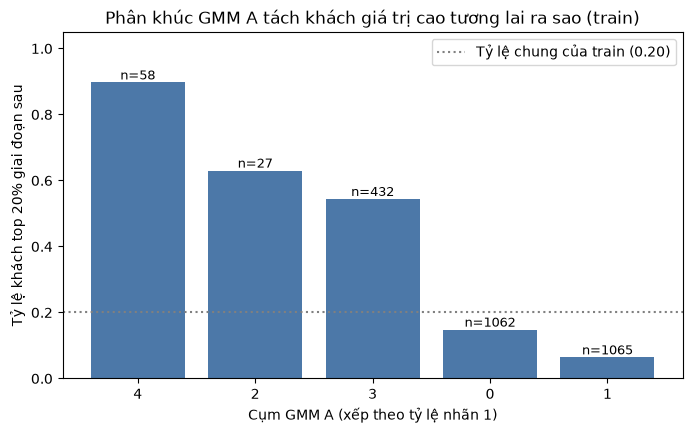

,so_khach,ty_le_nhan_1,Recency,Frequency,Monetary
cluster,,,,,
4,58,0.897,8.0,20.0,9428.285
2,27,0.630,83.0,6.0,8948.580
3,432,0.544,22.0,7.0,2462.490
0,1062,0.148,71.0,3.0,727.355
1,1065,0.064,142.0,1.0,225.700


In [15]:
info = gmm_info["GMM A (RFM thô)"]
prof = R_train.assign(cluster=info["hard"], y=y_train.to_numpy())
tbl = prof.groupby("cluster").agg(so_khach=("y", "size"), ty_le_nhan_1=("y", "mean"),
                                  Recency=("Recency", "median"), Frequency=("Frequency", "median"),
                                  Monetary=("Monetary", "median")).sort_values("ty_le_nhan_1", ascending=False)
tbl["ty_le_nhan_1"] = tbl["ty_le_nhan_1"].round(3)
results["gmm_a_profile"] = tbl.reset_index().round(3).to_dict("records")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(tbl.index.astype(str), tbl["ty_le_nhan_1"], color="#4C78A8")
ax.axhline(float(y_train.mean()), color="gray", ls=":", label=f"Tỷ lệ chung của train ({y_train.mean():.2f})")
for i, (c, r) in enumerate(tbl.iterrows()):
    ax.text(i, r["ty_le_nhan_1"], f"n={int(r['so_khach'])}", ha="center", va="bottom", fontsize=9)
ax.set(xlabel="Cụm GMM A (xếp theo tỷ lệ nhãn 1)", ylabel="Tỷ lệ khách top 20% giai đoạn sau",
       title="Phân khúc GMM A tách khách giá trị cao tương lai ra sao (train)", ylim=(0, 1.05))
ax.legend()
plt.savefig(FIG_DIR / "gmm_a_cluster_rate.png", dpi=150, bbox_inches="tight")
plt.show()
tbl

Chạy lại đúng quy tắc chọn của Thuận trên giai đoạn trước mốc, cấu hình A chọn `full`, k = 5 (cụm nhỏ nhất 27 khách) và cấu hình B chọn `diag`, k = 9 (cụm nhỏ nhất 78 khách), khác với k = 6 và k = 10 trên dữ liệu cả năm. Phân khúc GMM A tách khách giá trị cao tương lai khá rõ (tính trên train): cụm 4 (58 khách, mua gần đây, Frequency 20) có 89,7% khách thuộc top 20% ở giai đoạn sau, cụm 2 (27 khách chi nhiều nhưng lâu chưa mua) 63,0%, cụm 3 (432 khách) 54,4%. Hai cụm lớn nhất (2.127 khách, khoảng 80% train) chỉ đạt 14,8% và 6,4%.

## Đánh giá trên tập test

,PR-AUC,ROC-AUC,Precision@10%,Lift@10%,Recall@20%
XGBoost (11 feature),0.672,0.840,0.803,3.997,0.617
XGBoost (chỉ RFM),0.665,0.836,0.833,4.148,0.594
Random Forest (tham chiếu),0.672,0.838,0.848,4.223,0.586
GMM A (Thuận),0.634,0.814,0.773,3.846,0.586
GMM B (Thuận),0.634,0.808,0.803,3.997,0.564
Baseline: Monetary quá khứ,0.678,0.842,0.788,3.922,0.602
Ngẫu nhiên (tỷ lệ nhãn),0.201,0.500,0.201,1.000,0.200


,Precision,Recall,F1
XGBoost (11 feature),0.551,0.654,0.598
XGBoost (chỉ RFM),0.500,0.707,0.586
Random Forest (tham chiếu),0.611,0.579,0.595
Baseline: Monetary quá khứ >= P80 train,0.587,0.609,0.598


,So sánh (PR-AUC),Chênh,Cận dưới 95%,Cận trên 95%,Chứa 0
0,XGBoost (11 feature) − Baseline: Monetary quá khứ,-0.006,-0.030,0.015,True
1,XGBoost (11 feature) − Random Forest (tham chiếu),0.000,-0.015,0.016,True
2,XGBoost (11 feature) − XGBoost (chỉ RFM),0.007,-0.014,0.025,True
3,XGBoost (11 feature) − GMM A (Thuận),0.038,-0.001,0.073,True
4,XGBoost (chỉ RFM) − GMM A (Thuận),0.031,-0.005,0.068,True
5,GMM A (Thuận) − Baseline: Monetary quá khứ,-0.044,-0.078,-0.012,False


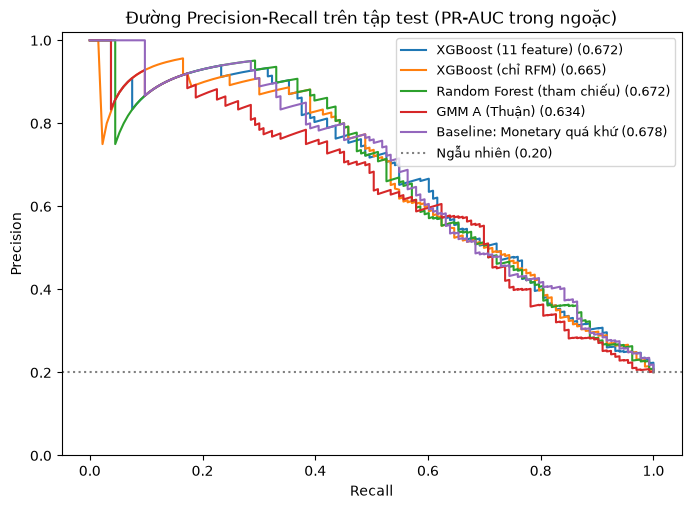

In [16]:
best_xgb, best_xgb_rfm = gs_xgb.best_estimator_, gs_xgb_rfm.best_estimator_
p_xgb = best_xgb.predict_proba(X_test)[:, 1]
p_xgb_rfm = best_xgb_rfm.predict_proba(X_test[RFM])[:, 1]

scores = {
    "XGBoost (11 feature)": p_xgb,
    "XGBoost (chỉ RFM)": p_xgb_rfm,
    "Random Forest (tham chiếu)": p_rf,
    "GMM A (Thuận)": score_gmm["GMM A (RFM thô)"],
    "GMM B (Thuận)": score_gmm["GMM B (log1p)"],
    "Baseline: Monetary quá khứ": score_base,
}
prev = float(y_test.mean())
rank_table = pd.DataFrame({k: rank_metrics(y_test, v) for k, v in scores.items()}).T
rank_table.loc["Ngẫu nhiên (tỷ lệ nhãn)"] = [prev, 0.5, prev, 1.0, 0.20]

# F1 ở ngưỡng chọn trên OOF của train, chỉ cho mô hình có xác suất nhãn (GMM không có cách chọn tương ứng)
models_thr = {"XGBoost (11 feature)": (best_xgb, X_train, X_test), "XGBoost (chỉ RFM)": (best_xgb_rfm, X_train[RFM], X_test[RFM]),
              "Random Forest (tham chiếu)": (rf_ref, X_train, X_test)}
cls_rows, thr_rows = {}, {}
for name, (mdl, Xtr_, Xte_) in models_thr.items():
    thr_f1, oof_f1 = oof_threshold(mdl, Xtr_, y_train)
    pred = (mdl.predict_proba(Xte_)[:, 1] >= thr_f1).astype(int)
    cls_rows[name] = class_metrics(y_test, pred); thr_rows[name] = {"thr": thr_f1, "oof_f1": oof_f1}
cls_rows["Baseline: Monetary quá khứ >= P80 train"] = class_metrics(y_test, pred_base)
class_table = pd.DataFrame(cls_rows).T

# Bootstrap 1.000 lần (cùng mẫu cho mọi mô hình) cho chênh lệch PR-AUC
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
names = list(scores)
boot = {n: [] for n in names}
for _ in range(1000):
    ix = rng.integers(0, len(yt), len(yt))
    if yt[ix].sum() == 0:
        continue
    for n in names:
        boot[n].append(average_precision_score(yt[ix], scores[n][ix]))
boot = {n: np.array(v) for n, v in boot.items()}
pairs = [("XGBoost (11 feature)", "Baseline: Monetary quá khứ"), ("XGBoost (11 feature)", "Random Forest (tham chiếu)"),
         ("XGBoost (11 feature)", "XGBoost (chỉ RFM)"), ("XGBoost (11 feature)", "GMM A (Thuận)"),
         ("XGBoost (chỉ RFM)", "GMM A (Thuận)"), ("GMM A (Thuận)", "Baseline: Monetary quá khứ")]
ci_rows = []
for a, b in pairs:
    d = boot[a] - boot[b]
    lo, hi = np.percentile(d, [2.5, 97.5])
    ci_rows.append({"So sánh (PR-AUC)": f"{a} − {b}", "Chênh": float(rank_table.loc[a, "PR-AUC"] - rank_table.loc[b, "PR-AUC"]),
                    "Cận dưới 95%": float(lo), "Cận trên 95%": float(hi), "Chứa 0": bool(lo <= 0 <= hi)})
ci_table = pd.DataFrame(ci_rows)
ci_xgb = np.percentile(boot["XGBoost (11 feature)"], [2.5, 97.5])

results["test_rank"] = rank_table.round(4).to_dict("index")
results["test_cls"] = class_table.round(4).to_dict("index")
results["thresholds"] = thr_rows
results["bootstrap"] = ci_table.round(4).to_dict("records")
results["ci_xgb_pr_auc"] = ci_xgb.round(4).tolist()
results["confusion_xgb"] = confusion_matrix(y_test, (p_xgb >= thr_rows["XGBoost (11 feature)"]["thr"]).astype(int)).tolist()

display(rank_table.round(3))
display(class_table.round(3))
display(ci_table.round(3))

fig, ax = plt.subplots(figsize=(8, 5.5))
for n in ["XGBoost (11 feature)", "XGBoost (chỉ RFM)", "Random Forest (tham chiếu)", "GMM A (Thuận)", "Baseline: Monetary quá khứ"]:
    p, r, _ = precision_recall_curve(y_test, scores[n])
    ax.plot(r, p, label=f"{n} ({rank_table.loc[n, 'PR-AUC']:.3f})")
ax.axhline(prev, color="gray", ls=":", label=f"Ngẫu nhiên ({prev:.2f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Đường Precision-Recall trên tập test (PR-AUC trong ngoặc)", ylim=(0, 1.02))
ax.legend(loc="upper right", fontsize=9)
plt.savefig(FIG_DIR / "pr_curve_all.png", dpi=150, bbox_inches="tight")
plt.show()

Theo PR-AUC: baseline Monetary 0,678, Random Forest 0,672, XGBoost 11 feature 0,666, XGBoost chỉ RFM 0,660, GMM A và B cùng 0,634; tất cả vượt xa đoán ngẫu nhiên (0,20). Khoảng bootstrap 95% của PR-AUC XGBoost là [0,582; 0,745].

**XGBoost không vượt baseline:** chênh -0,012 so với baseline (khoảng [-0,036; 0,009] chứa 0) và -0,006 so với Random Forest (cũng chứa 0). Precision@10% là 0,803 (53/66 khách đúng) so với 56 của Random Forest và 52 của baseline; Recall@20% cao nhất (0,617, bắt đúng 82/133 khách) nhưng chỉ hơn baseline 2 khách. Các chênh lệch này quá nhỏ để kết luận.

**So với GMM của Thuận:** XGBoost hơn GMM A khoảng 0,032 PR-AUC (bản chỉ RFM hơn 0,026) nhưng khoảng bootstrap [-0,007; 0,067] vẫn chứa 0, nên chỉ là xu hướng. Chênh lệch có ý nghĩa thống kê duy nhất là GMM A thấp hơn baseline Monetary 0,044 (khoảng [-0,078; -0,012]); nguyên nhân hợp lý là GMM chỉ cho vài mức điểm (5 cụm) nên không xếp hạng được khách trong cùng cụm, còn Monetary xếp hạng mịn. XGBoost chỉ RFM (0,660) gần bằng bản 11 feature (0,666, chênh khoảng chứa 0), nên phần chênh với GMM chủ yếu đến từ cách chấm điểm chứ không phải từ 8 feature thêm.

**F1 ở ngưỡng chọn trên OOF:** XGBoost 0,591 (precision 0,544, recall 0,647), Random Forest 0,595, baseline 0,598. XGBoost nghiêng về recall: bắt đúng 86/133 khách giá trị cao và báo nhầm 72 khách. GMM không có xác suất nhãn tương ứng nên không tính F1, chỉ so sánh bằng các chỉ số xếp hạng.

## Mức độ quan trọng của feature (XGBoost và Random Forest)

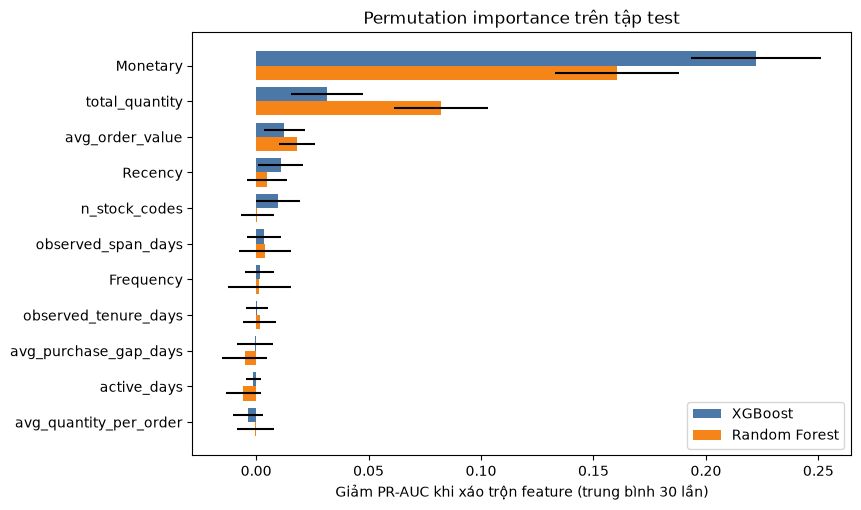

,feature,xgb_mean,xgb_std,rf_mean,rf_std
0,Monetary,0.2223,0.0290,0.1605,0.0276
1,total_quantity,0.0315,0.0159,0.0822,0.0210
2,avg_order_value,0.0126,0.0091,0.0183,0.0079
3,Recency,0.0109,0.0099,0.0048,0.0088
4,n_stock_codes,0.0095,0.0098,0.0005,0.0073
5,observed_span_days,0.0035,0.0075,0.0038,0.0116
6,Frequency,0.0017,0.0064,0.0013,0.0140
7,observed_tenure_days,0.0003,0.0048,0.0015,0.0072
8,avg_purchase_gap_days,-0.0005,0.0082,-0.0051,0.0099
9,active_days,-0.0012,0.0033,-0.0056,0.0077


In [17]:
def perm_table(model, X, name):
    p = permutation_importance(model, X, y_test, scoring="average_precision", n_repeats=30,
                               random_state=RANDOM_STATE, n_jobs=1)
    return pd.DataFrame({"feature": X.columns, f"{name}_mean": p.importances_mean, f"{name}_std": p.importances_std})

imp = (perm_table(best_xgb, X_test, "xgb").merge(perm_table(rf_ref, X_test, "rf"), on="feature")
       .sort_values("xgb_mean", ascending=False).reset_index(drop=True))
results["importance"] = imp.round(5).to_dict("records")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
d = imp.sort_values("xgb_mean")
yy = np.arange(len(d))
ax.barh(yy + 0.2, d["xgb_mean"], height=0.4, xerr=d["xgb_std"], label="XGBoost", color="#4C78A8")
ax.barh(yy - 0.2, d["rf_mean"], height=0.4, xerr=d["rf_std"], label="Random Forest", color="#F58518")
ax.set_yticks(yy); ax.set_yticklabels(d["feature"])
ax.set(xlabel="Giảm PR-AUC khi xáo trộn feature (trung bình 30 lần)", title="Permutation importance trên tập test")
ax.legend()
plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()
imp.round(4)

Monetary là feature duy nhất có tác động rõ với XGBoost (giảm PR-AUC 0,219, cao hơn 0,161 của Random Forest); total_quantity 0,029 (Random Forest 0,082). Các feature còn lại gần 0 hoặc âm ở cả hai mô hình, tức nằm trong nhiễu. Monetary và total_quantity tương quan cao nên hai mô hình chia vai trò giữa chúng theo cách khác nhau; kết luận chung là cả hai chủ yếu dựa vào quy mô chi tiêu quá khứ, khớp với việc baseline Monetary đã ngang bằng.

## Tổng hợp kết quả

In [18]:
from IPython.display import display, JSON
summary = rank_table[["PR-AUC", "ROC-AUC", "Precision@10%", "Recall@20%"]].round(3)
display(summary)
display(JSON(json.loads(json.dumps(results, default=lambda o: o.item() if hasattr(o, "item") else str(o)))))

,PR-AUC,ROC-AUC,Precision@10%,Recall@20%
XGBoost (11 feature),0.672,0.840,0.803,0.617
XGBoost (chỉ RFM),0.665,0.836,0.833,0.594
Random Forest (tham chiếu),0.672,0.838,0.848,0.586
GMM A (Thuận),0.634,0.814,0.773,0.586
GMM B (Thuận),0.634,0.808,0.803,0.564
Baseline: Monetary quá khứ,0.678,0.842,0.788,0.602
Ngẫu nhiên (tỷ lệ nhãn),0.201,0.500,0.201,0.200


<IPython.core.display.JSON object>

**Kết luận:** XGBoost (PR-AUC 0,666) tương đương Random Forest (0,672) và baseline Monetary quá khứ (0,678); chưa có bằng chứng nó tốt hơn. So với GMM của Thuận, XGBoost cao hơn khoảng 0,03 PR-AUC nhưng chưa đủ chắc chắn về thống kê; điều chắc chắn hơn là chấm điểm theo cụm GMM thấp hơn một quy tắc xếp hạng theo Monetary đơn giản.

**Cách đọc so sánh với Thuận:** GMM là phân cụm không giám sát, giá trị chính của nó là mô tả phân khúc chứ không phải dự đoán. Kết quả cho thấy phân khúc đó vẫn mang thông tin dự báo (trên train, cụm VIP có 89,7% khách thuộc top 20% giai đoạn sau, cụm mua một lần chỉ 6,4%), nên hai phần bổ sung cho nhau thay vì mâu thuẫn.

**Giới hạn:**
- Một mốc cắt và test 662 khách nên khoảng bootstrap rộng; mọi chênh lệch giữa các mô hình đều nhỏ hơn độ rộng này, trừ GMM A so với baseline
- Cả bốn siêu tham số tốt nhất của XGBoost nằm ở biên lưới, chưa thử mô hình đơn giản hơn nữa
- GMM được chọn lại k trên giai đoạn trước mốc (A: full k=5, B: diag k=9) nên khác cấu hình trên dữ liệu cả năm của Thuận; Monetary của GMM là bản gộp (chưa trừ hủy) theo định nghĩa của Thuận, còn XGBoost dùng bản đã trừ hủy
- Điểm GMM dùng tỷ lệ nhãn của train nên ở đây GMM hoạt động như bộ phân loại bán giám sát, không còn là mô hình thuần không giám sát
- Cohort dựa trên cleaning legacy chưa được nhóm duyệt

**Hướng tiếp theo (chưa làm):** thêm feature theo thời gian gần, thử nhiều mốc cắt, mở rộng lưới XGBoost về phía mô hình nông hơn (`max_depth=1`).